In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import umap

# ==========================================
# 0. Path Definitions & Style
# ==========================================
BASE_DIR = Path('/kyb/agpd/wwang/data/')
OUT_DIR = Path('/kyb/agpd/wwang/sst-pomdp/outputs/')

# LaTeX Display Names for Plots
PARAM_DISPLAY_NAMES = {
    'q_d_n': r"$\chi'$",
    'q_d': r"$\chi$",
    'q_s_n': r"$\sigma'$",
    'q_s': r"$\sigma$",
    'cost_stop_error': r"$c_{\mathrm{se}}$",
    'cost_time': r"$c_t$",
}

Running Version 1: Raw Embedding UMAP...


/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



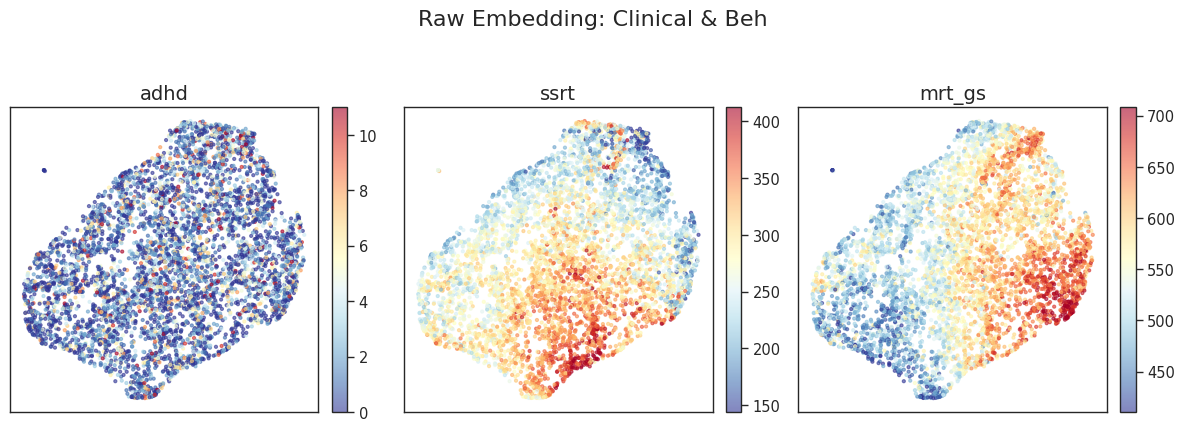

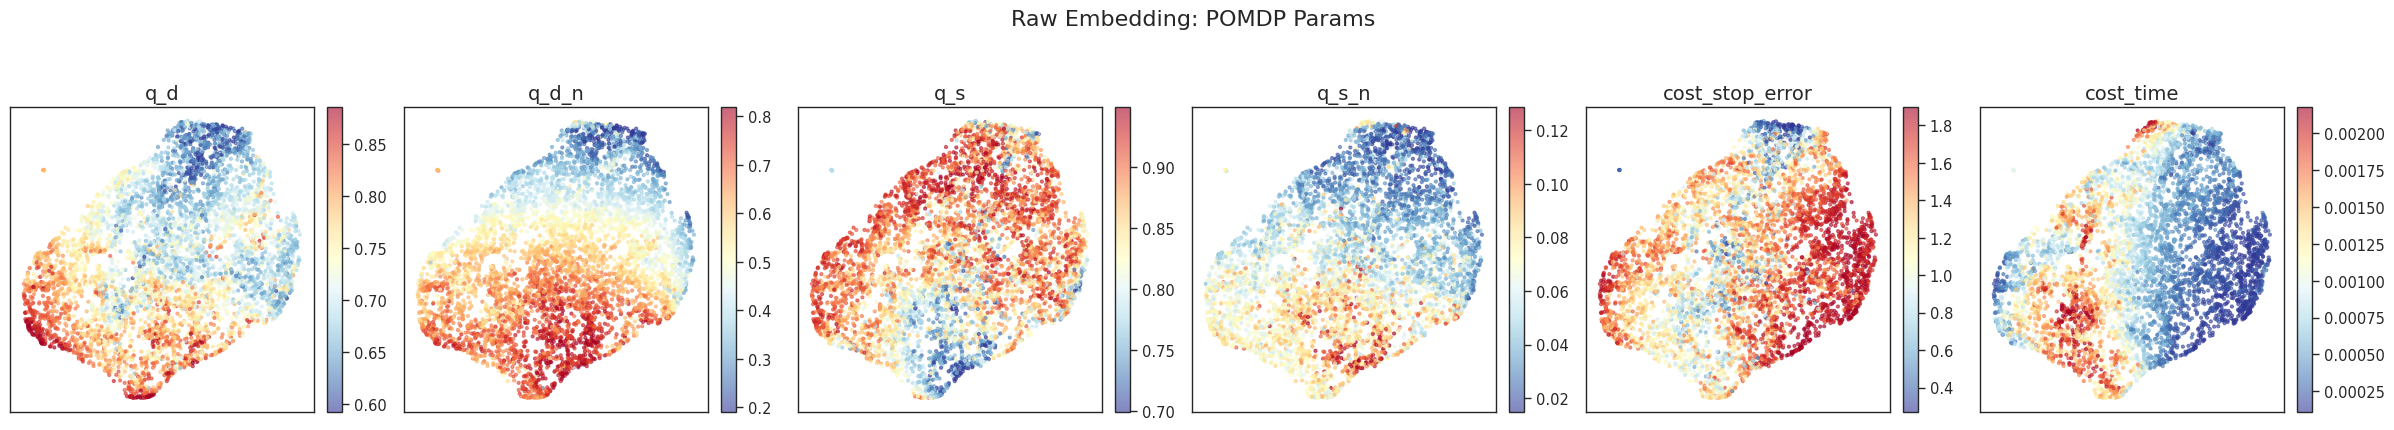

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
import umap

# ==========================================
# 1. 数据加载与对齐
# ==========================================
def prepare_data():
    df_emb = pd.read_csv(OUT_DIR / 'embeddings.csv')
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')

    # 统一格式并 Pivot 参数表
    df_post['year'] = df_post['subject_year'].astype(str)
    df_post_pivot = df_post.pivot_table(index=['subject_id', 'year'], 
                                        columns='param', values='mean').reset_index()
    
    df_emb['year'] = df_emb['year'].astype(str)
    df_stats['year'] = df_stats['year'].astype(str)
    
    # 合并
    df = pd.merge(df_emb, df_stats, on=['subject_id', 'year', 'filename'])
    df = pd.merge(df, df_post_pivot, on=['subject_id', 'year'])
    
    # 定义列名
    emb_cols = [c for c in df.columns if c.startswith('emb_')]
    param_cols = ['q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']
    clinical_cols = ['adhd', 'ssrt', 'mrt_gs']
    
    df_clean = df.dropna(subset=emb_cols + param_cols + clinical_cols).copy()
    return df_clean, emb_cols, param_cols, clinical_cols

df_final, emb_cols, param_cols, clinical_cols = prepare_data()

# ==========================================
# 绘图辅助函数 (直接使用原始变量名)
# ==========================================
def plot_grid(df, x_col, y_col, targets, title, filename):
    n = len(targets)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    for i, var in enumerate(targets):
        vmin, vmax = df[var].quantile([0.01, 0.99])
        sc = axes[i].scatter(df[x_col], df[y_col], c=df[var], 
                             s=5, alpha=0.6, cmap='RdYlBu_r', vmin=vmin, vmax=vmax)
        axes[i].set_title(var, fontsize=14)
        axes[i].set_xticks([]); axes[i].set_yticks([])
        plt.colorbar(sc, ax=axes[i], fraction=0.046, pad=0.04)
    plt.suptitle(title, y=1.05, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{filename}.png", dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# VERSION 1: Raw Embedding UMAP (不使用 CCA)
# ==========================================
print("Running Version 1: Raw Embedding UMAP...")
X_raw = StandardScaler().fit_transform(df_final[emb_cols])
reducer_raw = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
u_raw = reducer_raw.fit_transform(X_raw)

df_final['raw_u1'] = u_raw[:, 0]
df_final['raw_u2'] = u_raw[:, 1]

# 看看临床指标
plot_grid(df_final, 'raw_u1', 'raw_u2', ['adhd', 'ssrt', 'mrt_gs'], 
          "Raw Embedding: Clinical & Beh", "v1_raw_clinical")
# 看看六个参数
plot_grid(df_final, 'raw_u1', 'raw_u2', param_cols, 
          "Raw Embedding: POMDP Params", "v1_raw_params")


In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
import umap

# ==========================================
# 1. 准备数据 (整合 CBCL, Stats, Params)
# ==========================================
# 确保我们要染色的变量都在里面
color_targets = [
    'adhd', 'ssrt', 'mrt_gs', 
    'q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']

# ==========================================
# 2. 运行 3D UMAP
# ==========================================
print("正在计算 3D UMAP (Raw Embedding)...")
emb_cols = [c for c in df_final.columns if c.startswith('emb_')]
X_raw = StandardScaler().fit_transform(df_final[emb_cols])

reducer_3d = umap.UMAP(
    n_components=3, 
    n_neighbors=30, 
    min_dist=0.1, 
    random_state=42
)
u_3d = reducer_3d.fit_transform(X_raw)

df_final['u1'] = u_3d[:, 0]
df_final['u2'] = u_3d[:, 1]
df_final['u3'] = u_3d[:, 2]

# ==========================================
# 3. 创建带有下拉菜单的 Plotly 交互图
# ==========================================
def create_interactive_3d(df, targets):
    # 创建初始画布 (默认用 SSRT 染色)
    first_var = 'ssrt'
    
    # 过滤掉缺失值
    df_plot = df.dropna(subset=['u1', 'u2', 'u3'] + targets).copy()

    fig = go.Figure()

    # 添加散点图层
    fig.add_trace(go.Scatter3d(
        x=df_plot['u1'],
        y=df_plot['u2'],
        z=df_plot['u3'],
        mode='markers',
        marker=dict(
            size=2,
            color=df_plot[first_var],
            colorscale='RdYlBu_r', # 红蓝配色，适合看梯度
            colorbar=dict(title=first_var, thickness=20),
            opacity=0.7
        ),
        # 鼠标悬停显示信息
        text=[f"ID: {sid}<br>ADHD: {a}<br>SSRT: {s:.1f}" 
              for sid, a, s in zip(df_plot['subject_id'], df_plot['adhd'], df_plot['ssrt'])],
        hoverinfo='text'
    ))

    # 构建下拉菜单按钮
    buttons = []
    for var in targets:
        # 计算该变量的 1% 和 99% 分位数，防止极端值把颜色拉平
        vmin, vmax = df_plot[var].quantile([0.01, 0.99])
        
        button = dict(
            method="restyle",
            label=var,
            args=[{
                "marker.color": [df_plot[var]],
                "marker.cmin": vmin,
                "marker.cmax": vmax,
                "marker.colorbar.title": var
            }]
        )
        buttons.append(button)

    # 添加菜单到布局
    fig.update_layout(
        updatemenus=[dict(
            buttons=buttons,
            direction="down",
            pad={"r": 10, "t": 10},
            showactive=True,
            x=0.1, xanchor="left", y=1.1, yanchor="top"
        )],
        title="Interactive 3D Policy Manifold (Raw Embedding)",
        scene=dict(
            xaxis=dict(visible=False),
            yaxis=dict(visible=False),
            zaxis=dict(visible=False),
            bgcolor='white'
        ),
        margin=dict(l=0, r=0, b=0, t=50)
    )

    # 保存为 HTML 文件
    fig.write_html("raw_embedding_3d_interactive.html")
    print("保存成功: raw_embedding_3d_interactive.html. 请用浏览器打开查看！")

# 运行绘图
create_interactive_3d(df_final, color_targets)

正在计算 3D UMAP (Raw Embedding)...


/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



保存成功: raw_embedding_3d_interactive.html. 请用浏览器打开查看！


/tmp/ipykernel_58995/2554004043.py:14: DtypeWarning:

Columns (124,128,132,136,140,144,148,152,156,160,164,168,172,176,180,184,188,192,196,200) have mixed types. Specify dtype option on import or set low_memory=False.



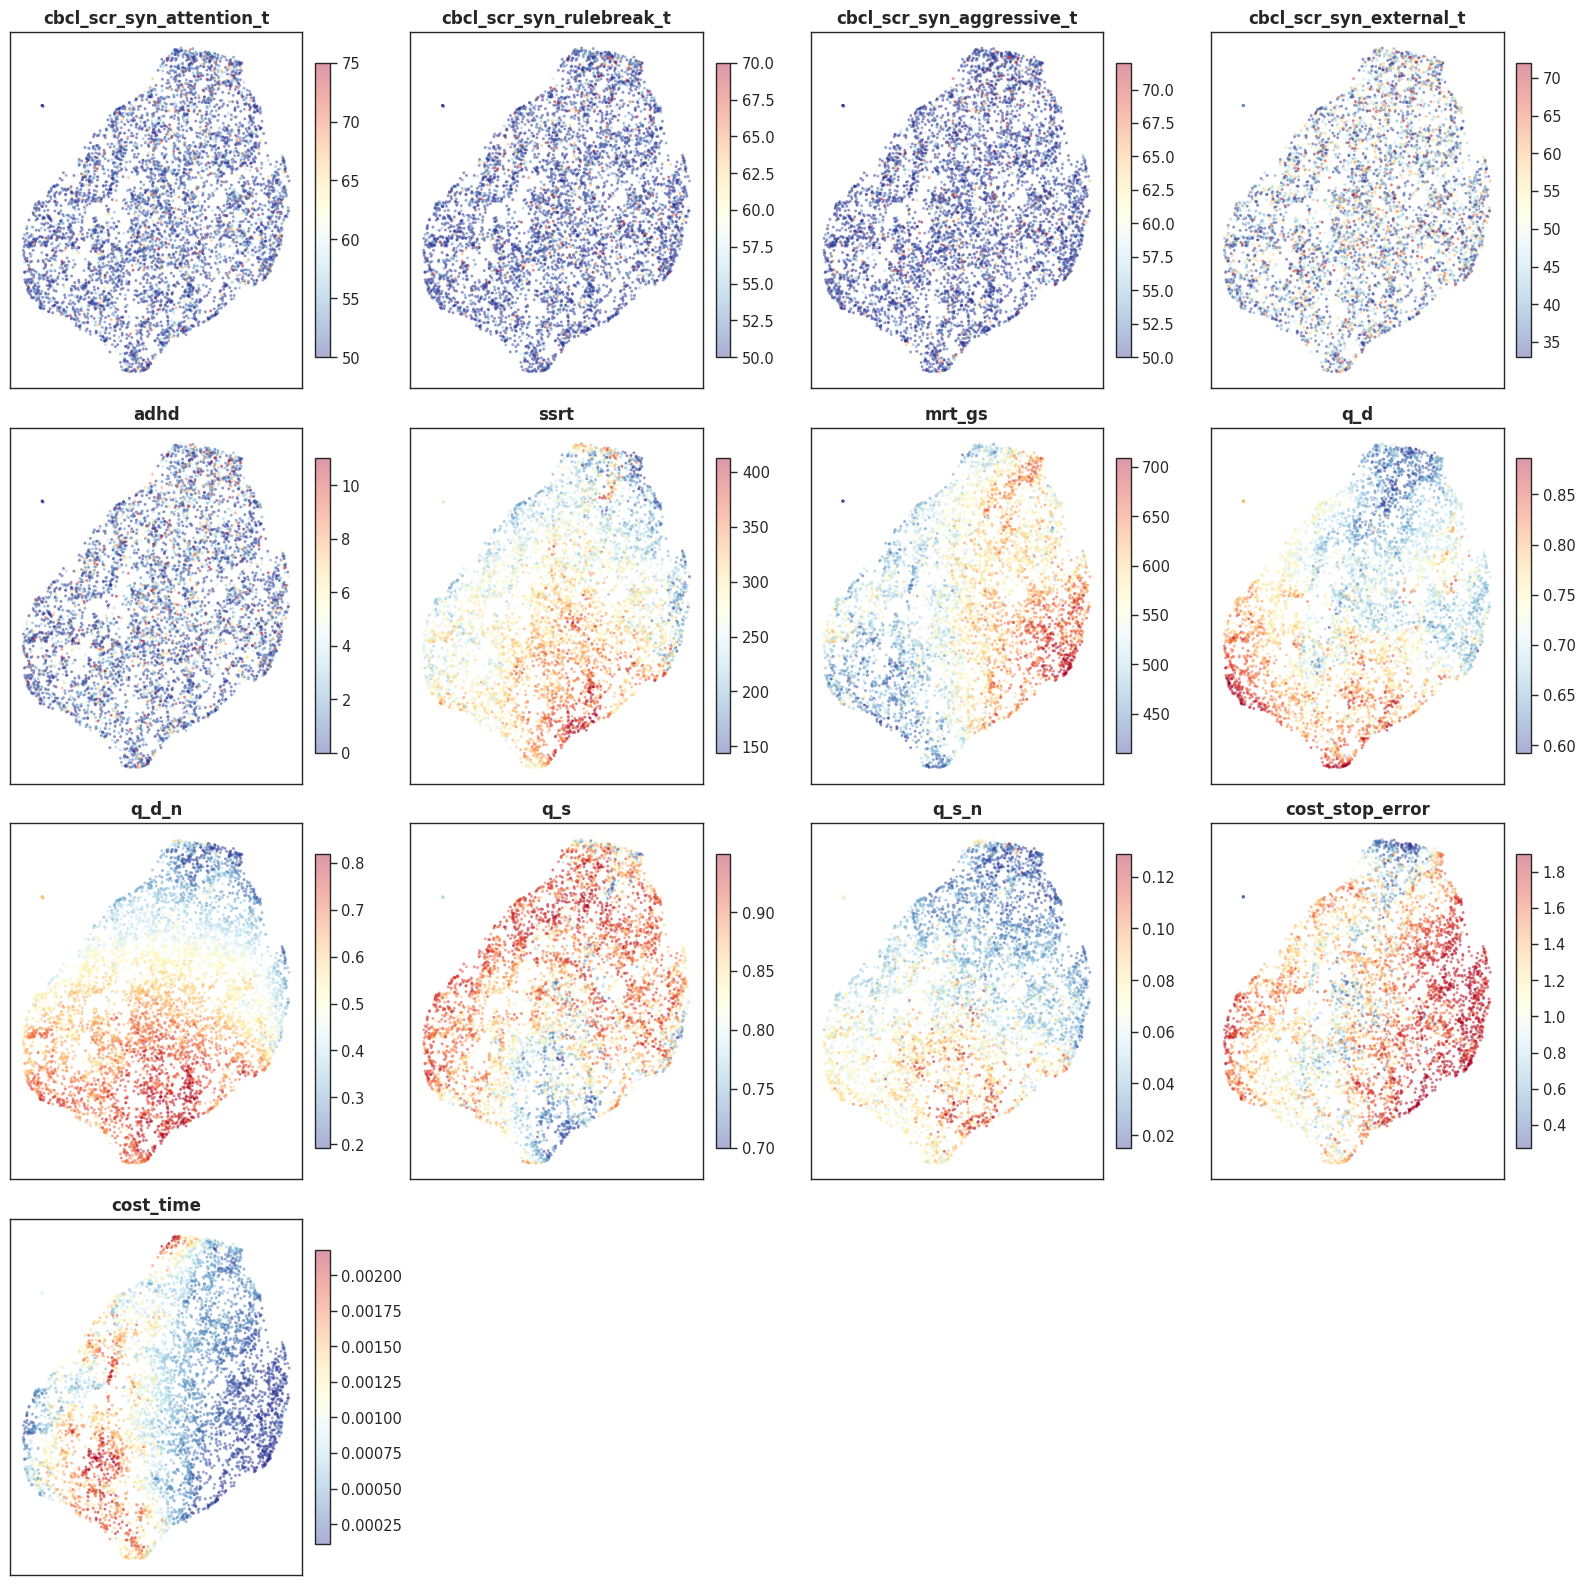

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import umap

# ==========================================
# 1. 整合 CBCL 与 Raw 行为数据
# ==========================================
def get_raw_manifold_data():
    # 读取你之前的 df_final (包含 emb, stats, post)
    # 如果还没有合并 CBCL，这里进行合并
    df_cbcl = pd.read_csv(BASE_DIR / 'mh_p_cbcl.csv')
    
    # 清洗 ID: NDAR_INV... -> INV...
    df_cbcl['subject_id'] = df_cbcl['src_subject_id'].str.replace('NDAR_', '')
    
    # 映射时间点: baseline_year_1_arm_1 -> baseline
    event_map = {'baseline_year_1_arm_1': 'baseline'}
    df_cbcl['year'] = df_cbcl['eventname'].map(event_map)
    
    # 选择 CBCL 核心亚型 (T分数)
    cbcl_vars = [
        'cbcl_scr_syn_attention_t',   # 注意力缺陷 (Inattentive)
        'cbcl_scr_syn_rulebreak_t',   # 违纪/冲动 (Impulsive/Hyperactive)
        'cbcl_scr_syn_aggressive_t',
        'cbcl_scr_syn_external_t'      # 外部化总分
    ]
    
    # 合并到你的主表 (假设主表叫 df_final)
    df_plot = pd.merge(df_final, df_cbcl[['subject_id', 'year'] + cbcl_vars], 
                       on=['subject_id', 'year'], how='inner')
    
    return df_plot, cbcl_vars

df_manifold, cbcl_vars = get_raw_manifold_data()

# ==========================================
# 2. 在同一个 UMAP 空间里绘制三个视角
# ==========================================
# 假设你已经算好了 raw_u1, raw_u2 (Raw Embedding 的 UMAP 坐标)

def plot_triple_view(df, u1, u2):
    # 我们画三排图，对比看
    
    # 第一排：临床亚型 (CBCL) - 看看是不是真的“散”
    view_clinical = cbcl_vars + ['adhd']
    
    # 第二排：行为指标 - 看看 SSRT 的梯度
    view_behavior = ['ssrt', 'mrt_gs']
    
    # 第三排：计算参数 (Policy Manifold) - 看看机制的梯度
    view_params = ['q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']
    
    all_targets = view_clinical + view_behavior + view_params
    n = len(all_targets)
    ncols = 4
    nrows = (n + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
    axes = axes.flatten()
    
    for i, var in enumerate(all_targets):
        # 颜色映射：使用百分位避免极端值干扰
        vmin, vmax = df[var].quantile([0.01, 0.99])
        
        sc = axes[i].scatter(df[u1], df[u2], c=df[var], 
                             s=2, alpha=0.4, cmap='RdYlBu_r', vmin=vmin, vmax=vmax)
        
        axes[i].set_title(var, fontsize=12, fontweight='bold')
        axes[i].set_xticks([]); axes[i].set_yticks([])
        plt.colorbar(sc, ax=axes[i], fraction=0.046, pad=0.04)
        
    for j in range(i + 1, len(axes)): axes[j].axis('off')
    
    plt.tight_layout()
    plt.savefig("raw_manifold_triple_view.png", dpi=300)
    plt.show()

plot_triple_view(df_manifold, 'raw_u1', 'raw_u2')

In [121]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from pathlib import Path

# 注意：运行此代码需要安装 umap-learn 和 plotly
# pip install umap-learn plotly
import umap

# ==========================================
# 1. 数据集成与预处理
# ==========================================
def load_full_dataset():
    # 读取原始文件 (请根据你的本地路径修改)
    df_emb = pd.read_csv(OUT_DIR / 'embeddings.csv')
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')
    df_cbcl = pd.read_csv(BASE_DIR / 'mh_p_cbcl.csv')

    # A. 清理 CBCL ID 与 时间点
    df_cbcl['subject_id'] = df_cbcl['src_subject_id'].str.replace('NDAR_', '')
    event_map = {'baseline_year_1_arm_1': 'baseline'}
    df_cbcl['year'] = df_cbcl['eventname'].map(event_map)
    
    # 我们关注的 CBCL T-分数
    cbcl_vars = [
        'cbcl_scr_dsm5_adhd_t', 
        'cbcl_scr_syn_attention_t', 
        'cbcl_scr_syn_rulebreak_t', 
        'cbcl_scr_syn_aggressive_t',
        'cbcl_scr_syn_external_t'
    ]

    # B. Pivot 后验参数
    df_post['year'] = df_post['subject_year'].astype(str)
    df_post_pivot = df_post.pivot_table(index=['subject_id', 'year'], 
                                        columns='param', values='mean').reset_index()

    # C. 合并所有数据
    df = pd.merge(df_emb, df_stats, on=['subject_id', 'year', 'filename'])
    df = pd.merge(df, df_post_pivot, on=['subject_id', 'year'])
    df = pd.merge(df, df_cbcl[['subject_id', 'year'] + cbcl_vars], on=['subject_id', 'year'])
    
    emb_cols = [c for c in df.columns if c.startswith('emb_')]
    param_cols = ['q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']
    
    df_clean = df.dropna(subset=emb_cols + param_cols + cbcl_vars).copy()
    return df_clean, emb_cols, param_cols, cbcl_vars

# 加载数据
df_final, emb_cols, param_cols, cbcl_vars = load_full_dataset()

# ==========================================
# 2. 计算 3D UMAP (基于原始 Embedding)
# ==========================================
print("正在计算 3D UMAP，请稍候...")
X_raw = StandardScaler().fit_transform(df_final[emb_cols])

reducer_3d = umap.UMAP(
    n_components=3, 
    n_neighbors=30, 
    min_dist=0.1, 
    random_state=42
)
u_3d = reducer_3d.fit_transform(X_raw)

df_final['u1'] = u_3d[:, 0]
df_final['u2'] = u_3d[:, 1]
df_final['u3'] = u_3d[:, 2]

# ==========================================
# 3. 构建 Plotly 交互式 3D 图 (带下拉菜单)
# ==========================================
def create_3d_interactive(df, param_cols, cbcl_cols):
    # 定义所有可以用来染色的变量
    targets = ['ssrt', 'adhd'] + cbcl_cols + param_cols
    
    # 初始染色变量
    initial_var = 'ssrt'
    
    fig = go.Figure()

    # 添加 3D 散点图
    fig.add_trace(go.Scatter3d(
        x=df['u1'], y=df['u2'], z=df['u3'],
        mode='markers',
        marker=dict(
            size=2,
            color=df[initial_var],
            colorscale='RdYlBu_r', # 红蓝配色，适合看梯度
            colorbar=dict(title=initial_var, thickness=20),
            opacity=0.7,
            # 处理极端值，使颜色对比更清晰
            cmin=df[initial_var].quantile(0.01),
            cmax=df[initial_var].quantile(0.99)
        ),
        # 悬停显示关键信息
        text=[f"ID: {sid}<br>ADHD (CBCL): {a_t}<br>SSRT: {s:.1f}" 
              for sid, a_t, s in zip(df['subject_id'], df['cbcl_scr_dsm5_adhd_t'], df['ssrt'])],
        hoverinfo='text'
    ))

    # 构建下拉菜单按钮
    buttons = []
    for var in targets:
        vmin, vmax = df[var].quantile([0.01, 0.99])
        buttons.append(dict(
            method="restyle",
            label=var,
            args=[{
                "marker.color": [df[var]],
                "marker.cmin": vmin,
                "marker.cmax": vmax,
                "marker.colorbar.title": var
            }]
        ))

    # 布局设置
    fig.update_layout(
        updatemenus=[dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=0.1, xanchor="left", y=1.1, yanchor="top"
        )],
        title="3D Raw Embedding Manifold (Interactive)",
        scene=dict(
            xaxis=dict(visible=False),
            yaxis=dict(visible=False),
            zaxis=dict(visible=False),
            bgcolor='white'
        ),
        margin=dict(l=0, r=0, b=0, t=50)
    )

    # 保存文件
    output_file = "raw_3d_policy_manifold.html"
    fig.write_html(output_file)
    print(f"交互式 3D 图已保存至: {output_file}")

# 执行绘图
create_3d_interactive(df_final, param_cols, cbcl_vars)

/tmp/ipykernel_58995/2522897009.py:20: DtypeWarning:

Columns (124,128,132,136,140,144,148,152,156,160,164,168,172,176,180,184,188,192,196,200) have mixed types. Specify dtype option on import or set low_memory=False.

/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



正在计算 3D UMAP，请稍候...
交互式 3D 图已保存至: raw_3d_policy_manifold.html
